# Cross-Sectional Feature Engineering & Scaling Pipeline


1. Construct a causally-correct target variable: **1-day forward market-relative log return** ($y_{i,t} = r_{i, t \to t+1} - \bar{r}_t$).
2. Engineer **24 indicators** (plus a 6-column calendar block → 30 candidate features) across single-stock OHLCV, market macro, exogenous risk, and options.
3. Implement a **Two-Stage Causal Scaling Pipeline** (Cross-Sectional Z-Score for single stock; Rolling Time-Series Z-Score for macro) with causal same-day outlier clipping.
4. Perform **Two-Tier Feature Selection** (direction-learned univariate Profit Factor filter & Mutual Information screening).

In [65]:
import numpy as np
import pandas as pd
import talib as ta
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import norm
import warnings
warnings.filterwarnings("ignore")

# Set visualization parameters
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
print("Environment initialized successfully.")

Environment initialized successfully.


## Data Loading & Causal Target Variable Construction
Construct the forward 1-day market-neutral log return:
$$r_{i, t \to t+1} = \ln\left(\frac{\text{AdjClose}_{i, t+1}}{\text{AdjClose}_{i, t}}\right)$$
$$y_{i,t} = r_{i, t \to t+1} - \frac{1}{N} \sum_{j=1}^{N} r_{j, t \to t+1}$$
*Note: This target is strictly cross-sectionally demeaned and strictly forward-shifted per ticker.*

In [66]:
# Load base equity dataset
df = pd.read_csv("final_portfolio_data.csv", parse_dates=["Date"])
df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)

# ------------------------------------------------------------------
# Data-availability boundary. OptionMetrics year-partitions on WRDS lag
# ~1 year (optionm.opprcd2026 does not exist yet), so option features are
# real only through 2025-12-31. Truncate the panel there: everything
# downstream (macro pull window, WRDS query range, burn-in, split) derives
# from df's Date span and adapts automatically. This removes the structural
# 2026 NaN block at the source instead of imputing it.
# ------------------------------------------------------------------
ANALYSIS_END = pd.Timestamp("2025-12-31")
df = df[df["Date"] <= ANALYSIS_END].reset_index(drop=True)

# Compute 1-day forward log return per ticker
df["fwd_log_ret"] = df.groupby("Ticker")["Adj Close"].transform(
    lambda x: np.log(x.shift(-1) / x)
)

# Cross-sectional daily mean market return
df["cs_mean_ret"] = df.groupby("Date")["fwd_log_ret"].transform("mean")

# Market-neutral relative return target
df["target"] = df["fwd_log_ret"] - df["cs_mean_ret"]
df = df.drop(columns=["cs_mean_ret"])

print(f"Dataset Loaded: {df['Ticker'].nunique()} Tickers | Date Range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
print(f"Target Variable 'target' created with shape: {df.shape}")

Dataset Loaded: 20 Tickers | Date Range: 2021-07-26 to 2025-12-31
Target Variable 'target' created with shape: (22300, 10)


## Single-Stock Target-OHLCV Features
TA-Lib oscillators and Timothy Masters microstructure indicators, all derived from each stock's OHLCV bar.

| Group | Features |
|---|---|
| TA-Lib oscillators | RSI(14), MACD-hist, PPO, ROC(10), ADX(14) |
| Volatility / range | ATR/Close, Bollinger %B, realized-vol(20d), intraday range |
| Volume flow | relative volume, CMMA(5), CMMA(10), CMF(20) |
| Momentum | mom_5 (weekly), mom_21 (monthly) |

In [67]:
def compute_stock_features(group):
    c, h, l, v = group["Adj Close"], group["High"], group["Low"], group["Volume"]

    # TA-Lib Oscillators
    group["rsi_14"] = (ta.RSI(c, timeperiod=14) - 50.0) / 50.0
    group["macd_hist"] = np.arcsinh(ta.MACD(c)[2] / (c + 1e-8))
    group["ppo"] = ta.PPO(c) / 100.0
    group["roc_10"] = ta.ROC(c, timeperiod=10) / 100.0
    group["atr_norm"] = np.log1p(ta.ATR(h, l, c, timeperiod=14) / (c + 1e-8))
    group["adx_14"] = ta.ADX(h, l, c, timeperiod=14) / 100.0

    upper, middle, lower = ta.BBANDS(c, timeperiod=20)
    group["bollinger_pct_b"] = (c - lower) / (upper - lower + 1e-8)
    group["rel_volume"] = np.log1p(v / (v.rolling(20).mean() + 1e-8))
    # High-low intraday RANGE (volatility/microstructure proxy).
    group["intraday_range_pct"] = (h - l) / (c + 1e-8)

    # Timothy Masters: CMMA(10) and Chaikin Money Flow(20)
    group["cmma_10"] = (c - ta.SMA(c, timeperiod=10)) / (c + 1e-8)
    group['cmma_5'] = (c - ta.SMA(c, timeperiod=5)) / (c + 1e-8)
    ii = (2 * c - h - l) / (h - l + 1e-8) * v
    group["cmf_20"] = ii.rolling(20).sum() / (v.rolling(20).sum() + 1e-8)

    # Realized Volatility (20d, annualized)
    log_ret = np.log(c / (c.shift(1) + 1e-8))
    group["realized_vol_20"] = log_ret.rolling(20).std() * np.sqrt(252)

    # Autoregressive return lags at weekly (5d) and monthly (21d) horizons.
    # (PACF diagnostics show a near-white-noise target: these are economic
    #  conventions, not PACF-selected peaks.)
    group["mom_5"] = np.log(c / (c.shift(5) + 1e-8))
    group["mom_21"] = np.log(c / (c.shift(21) + 1e-8))
    return group

ticker_dfs = []
for ticker, grp in df.groupby("Ticker"):
    ticker_dfs.append(compute_stock_features(grp.copy()))
df = pd.concat(ticker_dfs, ignore_index=True).sort_values(["Date", "Ticker"]).reset_index(drop=True)

## Macro & Market-Level Feature

In [68]:
start_date = df["Date"].min().strftime("%Y-%m-%d")
end_date = (df["Date"].max() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # plus one day to ensure we capture the last date in the range

# ^GSPC is fetched to build stock-specific risk features (beta, idio-vol) next.
macro_map = {"^VIX": "vix_level", "^GSPC": "sp500_close"}

m_raw = yf.download(list(macro_map.keys()), start=start_date, end=end_date, progress=False)
if isinstance(m_raw.columns, pd.MultiIndex):
    m_raw = m_raw["Close"] if "Close" in m_raw.columns.levels[0] else m_raw["Adj Close"]
m_raw = m_raw.rename(columns=macro_map).reset_index()

# Market-wide feature retained per proposal
m_raw["vix_5d_change"] = m_raw["vix_level"] - m_raw["vix_level"].shift(5)
# Market daily log return
m_raw["mkt_ret"] = np.log(m_raw["sp500_close"] / (m_raw["sp500_close"].shift(1) + 1e-8))

macro_cols = ["vix_5d_change"]  # only market-wide feature retained
df = pd.merge(df, m_raw[["Date"] + macro_cols + ["mkt_ret"]], on="Date", how="left")
# forward-fill macroeconomic features to handle missing values (e.g., weekends, holidays)
df[macro_cols + ["mkt_ret"]] = df[macro_cols + ["mkt_ret"]].ffill()

In [69]:
# Exogenous risk-model & sector features.
# These features include beta, idiosyncratic volatility, and sector-relative returns. 
# They are computed using rolling windows and groupby operations to capture the risk characteristics of each stock relative to the market and its sector peers.

df["log_ret"] = df.groupby("Ticker")["Adj Close"].transform(
    lambda x: np.log(x / (x.shift(1) + 1e-8))
)

def add_risk_features(g):
    cov = g["log_ret"].rolling(60).cov(g["mkt_ret"])
    var = g["mkt_ret"].rolling(60).var()
    g["beta_60"] = cov / (var + 1e-8)
    resid = g["log_ret"] - g["beta_60"] * g["mkt_ret"]
    g["idio_vol_60"] = resid.rolling(60).std() * np.sqrt(252)
    g["ret_21d"] = np.log(g["Adj Close"] / (g["Adj Close"].shift(21) + 1e-8))
    return g

df = df.groupby("Ticker", group_keys=False).apply(add_risk_features)

In [ ]:
# Sector-related indicators, including sector-relative returns. 
# These features are computed using a mapping of tickers to sectors, and they help capture the performance of a stock relative to its sector peers.
SECTOR_ALIASES = {
    "Financial Services": "Financials",
    "Consumer Cyclical": "Consumer Discretionary",
    "Consumer Defensive": "Consumer Staples",
    "Basic Materials": "Materials",
}

SECTOR_MAP = {
    "BLKB": "Technology", "BOOT": "Consumer Discretionary", "CACC": "Financials",
    "CALM": "Consumer Staples", "CNXC": "Technology", "EWBC": "Financials",
    "EXP": "Materials", "FTI": "Energy", "HNI": "Industrials", "LQDA": "Healthcare",
    "MDU": "Utilities", "NGS": "Energy", "RGA": "Financials", "RSI": "Consumer Discretionary",
    "SAIA": "Industrials", "STRL": "Industrials", "TWLO": "Technology",
    "USLM": "Materials", "WSBC": "Financials", "XPO": "Industrials",
}

def fetch_sector(tkr):
    if tkr in SECTOR_MAP:
        return SECTOR_MAP[tkr]
    try:
        s = yf.Ticker(tkr).info.get("sector")
        return SECTOR_ALIASES.get(s, s) or "Unknown"
    except Exception:
        return "Unknown"

sectors = {t: fetch_sector(t) for t in df["Ticker"].unique()}
df["Sector"] = df["Ticker"].map(sectors)
print("Sector assignment (authoritative GICS map):", sectors)

# Sector-relative 21d return (equal-weight sector basket within the 20-stock universe)..
sector_group_size = df.groupby(["Date", "Sector"])["ret_21d"].transform("size")
sector_mean_21d = df.groupby(["Date", "Sector"])["ret_21d"].transform("mean")
# Single-member sectors (CALM, LQDA, MDU) have no peers, so we set their sector-relative return to 0.0 to avoid misleading signals.
df["sector_rel_21"] = np.where(sector_group_size > 1, df["ret_21d"] - sector_mean_21d, 0.0)

# Drop intermediates
df = df.drop(columns=["log_ret", "ret_21d", "mkt_ret"])

exog_risk_cols = ["beta_60", "idio_vol_60", "sector_rel_21"]
print(f"Exogenous risk features computed: {exog_risk_cols}")

Sector assignment (authoritative GICS map): {'BLKB': 'Technology', 'BOOT': 'Consumer Discretionary', 'CACC': 'Financials', 'CALM': 'Consumer Staples', 'CNXC': 'Technology', 'EWBC': 'Financials', 'EXP': 'Materials', 'FTI': 'Energy', 'HNI': 'Industrials', 'LQDA': 'Healthcare', 'MDU': 'Utilities', 'NGS': 'Energy', 'RGA': 'Financials', 'RSI': 'Consumer Discretionary', 'SAIA': 'Industrials', 'STRL': 'Industrials', 'TWLO': 'Technology', 'USLM': 'Materials', 'WSBC': 'Financials', 'XPO': 'Industrials'}
Exogenous risk features computed: ['beta_60', 'idio_vol_60', 'sector_rel_21']


## WRDS OptionMetrics Features (exogenous, stock-specific)
Firm-specific option-market signals.

1. `stock_pcr` — put/call volume ratio (3-day median, clipped to `[0, 5]` to kill near-zero-denominator blow-ups)
2. `iv_30d` — 30-day ATM implied volatility
3. `iv_skew` — 25-delta IV skew (put IV − call IV)
4. `gex` — net gamma exposure (market-maker hedging pressure)
5. `bid_ask_spread` — ATM option quoted spread `(ask − bid) / mid`, an exogenous liquidity proxy for the underlying

In [72]:
# ==========================================================
# WRDS Connection (OptionMetrics only; short-interest intentionally omitted)
# Mapping path: ticker --crsp.msenames--> permno --opcrsphist--> secid
# then year-partitioned option chains optionm.opprcdYYYY
# ==========================================================
import wrds
import numpy as np
import pandas as pd

def to_sql_tuple(iterable):
    """Formats Python iterables into safe SQL IN clauses, preventing 1-element tuple syntax errors."""
    items = list(iterable)
    if not items:
        return "('')"
    if len(items) == 1:
        item = items[0]
        return f"('{item}')" if isinstance(item, str) else f"({item})"
    return str(tuple(items))

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)

# WRDS username: read from the WRDS_USERNAME environment variable first
# (e.g. `export WRDS_USERNAME=yourid` before launching Jupyter), and only
# prompt interactively as a fallback. Never hardcode/commit a real username
# in a shared notebook.
import os
import getpass

WRDS_USERNAME = os.environ.get("WRDS_USERNAME") or getpass.getpass("WRDS username: ")
if not WRDS_USERNAME:
    raise ValueError(
        "WRDS_USERNAME is blank -> db=None -> NO WRDS data will be pulled.\n"
        "Set the WRDS_USERNAME environment variable (or enter it at the prompt) and re-run."
    )

db = wrds.Connection(wrds_username=WRDS_USERNAME)

tickers   = tuple(df["Ticker"].unique().tolist())
start_str = df["Date"].min().strftime("%Y-%m-%d")
end_str   = df["Date"].max().strftime("%Y-%m-%d")
yr_lo, yr_hi = df["Date"].min().year, df["Date"].max().year
print(f"Querying WRDS for {len(tickers)} tickers | {start_str} -> {end_str}")

Loading library list...
Done
Querying WRDS for 20 tickers | 2021-07-26 -> 2025-12-31


In [73]:
# 0) ticker -> permno (CRSP msenames, active during window)
permno_df = pd.DataFrame()
try:
    permno_df = db.raw_sql(f"""
        SELECT permno, ticker FROM crsp.msenames
        WHERE ticker IN {to_sql_tuple(tickers)}
          AND namedt <= '{end_str}' AND nameendt >= '{start_str}'
    """)
    print(f"[1] permno resolved: {permno_df['ticker'].nunique()}/{len(tickers)} tickers")
except Exception as e:
    print(f"[1] crsp.msenames lookup failed: {e}")

# 1) permno -> secid (WRDS CRSP-OptionMetrics link: opcrsphist)
secid_map = pd.DataFrame()
if not permno_df.empty:
    permnos = permno_df["permno"].dropna().astype(int).unique().tolist()
    try:
        link_df = db.raw_sql(f"""
            SELECT secid, permno, sdate, edate
            FROM wrdsapps_link_crsp_optionm.opcrsphist
            WHERE permno IN {to_sql_tuple(permnos)}
              AND sdate <= '{end_str}' AND edate >= '{start_str}'
        """)
        secid_map = permno_df.merge(link_df, on="permno")
        print(f"[2] secid links: {len(secid_map)} rows | tickers: {secid_map['ticker'].nunique()}")

        if not secid_map.empty:
            # A ticker can map to >1 secid if CRSP has multiple overlapping
            # permno/secid link rows in this window (e.g. a ticker symbol
            # reused by a different company). Left undeduplicated, the later
            # groupby(["ticker", "date"]) aggregations would silently sum
            # volume/gamma across unrelated instruments. Keep only the link
            # whose [sdate, edate] window overlaps our analysis window most.
            win_start, win_end = pd.Timestamp(start_str), pd.Timestamp(end_str)
            secid_map["sdate"] = pd.to_datetime(secid_map["sdate"])
            secid_map["edate"] = pd.to_datetime(secid_map["edate"])
            overlap_start = secid_map["sdate"].clip(lower=win_start)
            overlap_end = secid_map["edate"].clip(upper=win_end)
            secid_map["overlap_days"] = (overlap_end - overlap_start).dt.days.clip(lower=0)

            dupe_counts = secid_map.groupby("ticker")["secid"].nunique()
            ambiguous = dupe_counts[dupe_counts > 1].index.tolist()
            if ambiguous:
                print(f"[2] WARNING: multiple secid candidates for {ambiguous} "
                      f"-> keeping the link with the largest date overlap for each.")

            secid_map = (secid_map.sort_values("overlap_days", ascending=False)
                         .drop_duplicates(subset="ticker", keep="first")
                         .drop(columns=["overlap_days"]))
            print(f"[2] secid links after dedup: {len(secid_map)} rows | tickers: {secid_map['ticker'].nunique()}")
    except Exception as e:
        print(f"[2] opcrsphist link failed: {e}")

secids = secid_map["secid"].dropna().astype(int).unique().tolist() if not secid_map.empty else []
print(f"[2] unique secids to query: {len(secids)}")

# Probe for a QUOTED-SPREAD column PAIR: need BOTH best_bid and an ask-side column.
# Only feeds bid_ask_spread. If the pair is absent, that ONE feature stays NaN and the
# core option pull below is completely unaffected.
ask_col = None
try:
    probe = db.raw_sql(
        "SELECT column_name FROM information_schema.columns "
        "WHERE table_schema='optionm' AND table_name='opprcd2024'"
    )
    avail = set(probe["column_name"])
    if "best_bid" in avail:
        for cand in ["best_offer", "best_ask"]:
            if cand in avail:
                ask_col = cand
                break
    print(f"[2] option quote pair: best_bid + {ask_col}")
except Exception as e:
    print(f"[2] quote-column probe skipped: {e}")

# 2) Pull option chains per year.
extra_select = f", best_bid, {ask_col} AS ask" if ask_col else ""

def _pull_year(y, with_quotes):
    sel = extra_select if with_quotes else ""
    return db.raw_sql(f"""
        SELECT secid, date, cp_flag, volume, open_interest,
               impl_volatility AS iv, delta, gamma{sel}
        FROM optionm.opprcd{y}
        WHERE secid IN {to_sql_tuple(secids)}
          AND date BETWEEN '{start_str}' AND '{end_str}'
          AND volume > 0
    """, date_cols=["date"])

opt_parts = []
if secids:
    for y in range(yr_lo, yr_hi + 1):
        try:
            part = _pull_year(y, with_quotes=bool(extra_select))
            tag = " (+quotes)" if extra_select else ""
            print(f"[3]   optionm.opprcd{y}: {len(part):,} rows{tag}")
            opt_parts.append(part)
        except Exception as e:
            if extra_select:
                # Quote-enriched query failed (e.g. best_bid not a column in this vintage).
                # Retry the proven plain select so core features survive.
                try:
                    part = _pull_year(y, with_quotes=False)
                    print(f"[3]   optionm.opprcd{y}: {len(part):,} rows (quotes dropped: {e})")
                    opt_parts.append(part)
                except Exception as e2:
                    print(f"[3]   optionm.opprcd{y} skipped: {e2}")
            else:
                print(f"[3]   optionm.opprcd{y} skipped: {e}")

if opt_parts:
    opt = pd.concat(opt_parts, ignore_index=True)
    opt["date"] = pd.to_datetime(opt["date"])
    opt = opt.merge(secid_map[["secid", "ticker"]].drop_duplicates(), on="secid")
    spot = df[["Ticker", "Date", "Adj Close"]].rename(
        columns={"Ticker": "ticker", "Date": "date", "Adj Close": "spot"}
    )
    opt = opt.merge(spot, on=["ticker", "date"], how="left")
else:
    opt = pd.DataFrame()
print(f"[3] Option chain rows assembled: {len(opt):,}")

# 3) Put/Call Volume Ratio (stock_pcr) with outlier clipping
if not opt.empty:
    pcr = opt.groupby(["ticker", "date", "cp_flag"])["volume"].sum().unstack("cp_flag", fill_value=0)
    pcr.columns = [str(c).upper() for c in pcr.columns]
    calls = pcr["C"] if "C" in pcr.columns else 0
    puts  = pcr["P"] if "P" in pcr.columns else 0
    pcr["stock_pcr"] = puts / (calls + 1e-8)
    pcr = pcr.reset_index().rename(columns={"ticker": "Ticker", "date": "Date"})
    # 3-day median de-noise, then clip pathological blow-ups from near-zero call volume
    pcr["stock_pcr"] = pcr.groupby("Ticker")["stock_pcr"].transform(
        lambda x: x.rolling(3, min_periods=1).median()
    )
    pcr["stock_pcr"] = pcr["stock_pcr"].clip(lower=0.0, upper=5.0)
else:
    pcr = pd.DataFrame(columns=["Ticker", "Date", "stock_pcr"])

# 4) 30-day ATM IV (iv_30d) + 25-delta IV Skew (iv_skew)
if not opt.empty:
    opt["abs_delta"] = opt["delta"].abs()
    atm = (opt[(opt["abs_delta"] >= 0.45) & (opt["abs_delta"] <= 0.55)]
           .groupby(["ticker", "date"])["iv"].mean()
           .reset_index().rename(columns={"iv": "iv_30d", "ticker": "Ticker", "date": "Date"}))
    w25 = opt[(opt["abs_delta"] >= 0.20) & (opt["abs_delta"] <= 0.30)]
    put25  = w25[w25["cp_flag"] == "P"].groupby(["ticker", "date"])["iv"].mean()
    call25 = w25[w25["cp_flag"] == "C"].groupby(["ticker", "date"])["iv"].mean()
    skew = (put25 - call25).reset_index().rename(columns={"iv": "iv_skew", "ticker": "Ticker", "date": "Date"})
    iv_feat = atm.merge(skew, on=["Ticker", "Date"], how="outer")
else:
    iv_feat = pd.DataFrame(columns=["Ticker", "Date", "iv_30d", "iv_skew"])

# 5) Net Gamma Exposure (gex)
if not opt.empty:
    opt["gex_signed"] = (opt["gamma"] * opt["open_interest"] * (opt["spot"] ** 2) * 0.01) * np.where(opt["cp_flag"] == "C", 1, -1)
    gex = (opt.groupby(["ticker", "date"])["gex_signed"]
           .sum().reset_index()
           .rename(columns={"gex_signed": "gex", "ticker": "Ticker", "date": "Date"}))
else:
    gex = pd.DataFrame(columns=["Ticker", "Date", "gex"])

# 6) Bid-Ask Quoted Spread (ATM option quote -> exogenous liquidity proxy for the underlying)
if not opt.empty and ask_col and {"best_bid", "ask"}.issubset(opt.columns):
    qd = opt[(opt["abs_delta"] >= 0.45) & (opt["abs_delta"] <= 0.55) &
             (opt["best_bid"] > 0) & (opt["ask"] > 0)].copy()
    qd["mid"] = (qd["best_bid"] + qd["ask"]) / 2.0
    qd["spread"] = (qd["ask"] - qd["best_bid"]) / (qd["mid"] + 1e-8)
    ba = (qd.groupby(["ticker", "date"])["spread"].mean()
          .reset_index().rename(columns={"spread": "bid_ask_spread", "ticker": "Ticker", "date": "Date"}))
else:
    ba = pd.DataFrame(columns=["Ticker", "Date", "bid_ask_spread"])

# Merge option features
for feat in [pcr, iv_feat, gex, ba]:
    if not feat.empty:
        df = df.merge(feat, on=["Ticker", "Date"], how="left")

option_cols = ["stock_pcr", "iv_30d", "iv_skew", "gex", "bid_ask_spread"]
for col in option_cols:
    if col not in df.columns:
        df[col] = np.nan
    df[col] = df[col].astype(float)

# Causal forward-fill (option quotes are sparse): up to 5 trading days
df[option_cols] = df.groupby("Ticker")[option_cols].ffill(limit=5)

print(f"\nOption features merged: {option_cols}")
print(df[option_cols].describe().T[["count", "mean", "std"]])

[1] permno resolved: 20/20 tickers
[2] secid links: 28 rows | tickers: 20
[2] WARNING: multiple secid candidates for ['TWLO'] -> keeping the link with the largest date overlap for each.
[2] secid links after dedup: 20 rows | tickers: 20
[2] unique secids to query: 20
[2] option quote pair: best_bid + best_offer
[3]   optionm.opprcd2021: 83,382 rows (+quotes)
[3]   optionm.opprcd2022: 178,943 rows (+quotes)
[3]   optionm.opprcd2023: 161,174 rows (+quotes)
[3]   optionm.opprcd2024: 141,622 rows (+quotes)
[3]   optionm.opprcd2025: 112,461 rows (+quotes)
[3] Option chain rows assembled: 677,582

Option features merged: ['stock_pcr', 'iv_30d', 'iv_skew', 'gex', 'bid_ask_spread']
                  count         mean           std
stock_pcr       19713.0     0.978893      1.374101
iv_30d          16713.0     0.457614      0.192502
iv_skew         12840.0     0.047415      0.103027
gex             19713.0  3353.918032  16914.712194
bid_ask_spread  16681.0     0.296230      0.316188


In [74]:
notna = df[option_cols].notna()
notna["year"] = df["Date"].dt.year
cov_year = notna.groupby("year").mean()
print("Option-feature coverage (share non-NaN) by year:")
print(cov_year.round(3))

notna_t = df[option_cols].notna()
notna_t["Ticker"] = df["Ticker"].values
cov_ticker = notna_t.groupby("Ticker").mean()
print("\nCoverage by ticker:")
print(cov_ticker.round(3))

all_nan = df[option_cols].isna().all(axis=1)
if all_nan.any():
    block_dates = df.loc[all_nan, "Date"]
    print(f"\nEntire option block NaN: {all_nan.sum():,} rows ({all_nan.mean():.1%} of panel) "
          f"across {block_dates.nunique()} dates, {block_dates.min().date()} -> {block_dates.max().date()}")
else:
    print("\nNo structural all-NaN option block remaining in the panel.")

Option-feature coverage (share non-NaN) by year:
      stock_pcr  iv_30d  iv_skew    gex  bid_ask_spread
year                                                   
2021      0.943   0.765    0.591  0.943           0.765
2022      0.942   0.774    0.584  0.942           0.773
2023      0.941   0.790    0.582  0.941           0.786
2024      0.953   0.830    0.660  0.953           0.827
2025      0.672   0.597    0.469  0.672           0.597

Coverage by ticker:
        stock_pcr  iv_30d  iv_skew    gex  bid_ask_spread
Ticker                                                   
BLKB        0.924   0.648    0.130  0.924           0.647
BOOT        0.928   0.928    0.925  0.928           0.928
CACC        0.928   0.923    0.890  0.928           0.923
CALM        0.928   0.912    0.902  0.928           0.912
CNXC        0.928   0.919    0.840  0.928           0.919
EWBC        0.927   0.916    0.758  0.927           0.916
EXP         0.928   0.911    0.774  0.928           0.911
FTI         0.92

## Two-Stage Causal Scaling
1. **Stage 1 (element-wise):** variance-stabilizing transforms (asinh, log1p, /100) applied inline per indicator.
2. **Stage 2A (daily cross-sectional z-score):** every feature that **varies across tickers** — single-stock TA, momentum, WRDS options, and the exogenous risk set — is standardized across the $N=20$ stocks on date $t$: $Z_{i,t}=(X_{i,t}-\mu_t)/\sigma_t$. Same-day only → look-ahead-free.
3. **Stage 2B (60-day rolling time-series z-score):** the one market-wide feature (`vix_5d_change`), identical across tickers and therefore without cross-sectional variance, is standardized over a 60-day backward window.
4. **Calendar block:** day-of-week one-hot + month sin/cos, left unscaled and treated as one selectable unit downstream.

In [75]:
# Stage 1 (element-wise transforms): adjust for skewed distributions and outliers.
# The arcsinh transform is a smooth approximation to log(1+x) that handles negative values gracefully.
df["gex"] = np.arcsinh(df["gex"].astype(float))

# Stage 2A: daily cross-sectional z-score for every feature that VARIES across tickers
#           (single-stock TA + momentum, the exogenous risk set, and WRDS options).
stock_cols = [
    "rsi_14", "macd_hist", "ppo", "roc_10", "atr_norm", "adx_14",
    "bollinger_pct_b", "rel_volume", "intraday_range_pct", "cmma_10",
    "cmma_5", "cmf_20", "realized_vol_20", "mom_5", "mom_21",
] + exog_risk_cols + option_cols   # all cross-sectionally varying

for col in stock_cols:
    if col in df.columns:
        df[col] = df.groupby("Date")[col].transform(
            lambda x: (x - x.mean()) / (x.std() + 1e-8)
        )

# Stage 2B: 60-day rolling time-series z-score for the single market-wide feature.
# (Cross-sectional z-score is undefined for a feature identical across tickers.)
for col in macro_cols:
    df[col] = df.groupby("Ticker")[col].transform(
        lambda x: (x - x.rolling(60).mean()) / (x.rolling(60).std() + 1e-8)
    )

# Causal outlier control: clip extreme z-scores to +/-3.0 standard deviations so that the model is not dominated by a few extreme observations. 
# This is particularly important for features like option-implied volatility and net gamma exposure, which can exhibit heavy tails.
Z_CLIP = 3.0
for col in stock_cols + macro_cols:
    if col in df.columns:
        df[col] = df[col].clip(lower=-Z_CLIP, upper=Z_CLIP)

# Calendar block (left unscaled; selected/dropped as a unit downstream)
df["dow"] = df["Date"].dt.dayofweek
df = pd.get_dummies(df, columns=["dow"], prefix="dow", drop_first=True, dtype=float)
df["month_sin"] = np.sin(2 * np.pi * df["Date"].dt.month / 12.0)
df["month_cos"] = np.cos(2 * np.pi * df["Date"].dt.month / 12.0)

dow_cols = [c for c in df.columns if c.startswith("dow_")]
calendar_cols = dow_cols + ["month_sin", "month_cos"]

# Dense (populated after burn-in) vs sparse (NaN-tolerant -> pipeline imputer)
core_cols = [
    "rsi_14", "macd_hist", "ppo", "roc_10", "atr_norm", "adx_14",
    "bollinger_pct_b", "rel_volume", "intraday_range_pct", "cmma_10",
    "cmf_20", "realized_vol_20", "mom_5", "mom_21","cmma_5"
] + exog_risk_cols + macro_cols
sparse_cols = option_cols  # may contain NaN (2026 option gap, sparse quotes)

all_feature_cols = core_cols + sparse_cols + calendar_cols
n_exog = len(exog_risk_cols) + len(option_cols) + len(macro_cols)
print(f"Scaling complete. Candidate features: {len(all_feature_cols)} | exogenous: {n_exog} | z-clipped at +/-{Z_CLIP}")

Scaling complete. Candidate features: 30 | exogenous: 9 | z-clipped at +/-3.0


## Feature Selection — Profit Factor, Alpha, Mutual Information
Per the proposal: rank each candidate by univariate **Profit Factor**, drop the worst, and cross-check against training-set **mutual information**. The calendar block is protected (selected/dropped as a unit, not individually ranked).

- $\text{PF}=\sum\text{Gains}/\sum|\text{Losses}|$ on eval-half strategy returns (position = learned direction × sign of feature)
- Masters-style **Alpha**: mean eval-half strategy return, annualized, with t-stat / p-value (cross-sectionally correlated observations → treat p-values as indicative, not exact).
- **MI** via `mutual_info_regression` on the training split as a non-linear, direction-free cross-check.

*This table is a coarse pre-filter only: the ranking never sees the test split, and the final tunable re-selection (`SelectKBest`) sits inside each model pipeline during CV*

In [76]:
# Analysis set: require target + dense core features (burn-in rows dropped).
# Sparse option features may stay NaN -> handled pairwise here / by the pipeline imputer.
df_analysis = df.dropna(subset=["target"] + core_cols).copy()

# Final-12-months holdout (per proposal) with a 5-business-day embargo:
# 1-day forward targets overlap the next day's price path by construction,
# so the last train targets would otherwise realize INSIDE the test window.
# The embargo severs that boundary contamination.
split_date = df_analysis["Date"].max() - pd.DateOffset(months=12)
EMBARGO = pd.tseries.offsets.BDay(5)
train_df = df_analysis[df_analysis["Date"] <= split_date - EMBARGO].copy()
test_df = df_analysis[df_analysis["Date"] > split_date].copy()
print(f"Split boundary {split_date.date()} | embargo: {EMBARGO.n} business days")
print(f"Train: {train_df['Date'].min().date()} -> {train_df['Date'].max().date()} ({len(train_df)} rows)")
print(f"Test:  {test_df['Date'].min().date()} -> {test_df['Date'].max().date()} ({len(test_df)} rows)  [held out, unused below]")

Split boundary 2024-12-30 | embargo: 5 business days
Train: 2022-01-12 -> 2024-12-23 (14820 rows)
Test:  2024-12-31 -> 2025-12-30 (5000 rows)  [held out, unused below]


In [77]:
# Selection-internal fit/eval halves: train_df is split into two halves by date, so that feature selection can be performed on one half and evaluated on the other. 
# This helps to prevent overfitting and ensures that the selected features generalize well to unseen data.


# the spearmanr() function is used to compute the Spearman rank correlation coefficient, which measures the monotonic relationship between two variables. 
# The sign of this correlation is used to determine the direction of the feature's effect on the target variable.
# So We can learn the relationship between the feature and the target in a way that is not influenced by the evaluation data. This helps to avoid overfitting and ensures that the feature's effect is generalizable.
from scipy.stats import spearmanr
fit_end   = train_df["Date"].quantile(0.5, interpolation="nearest")
fit_half  = train_df[train_df["Date"] <= fit_end]
eval_half = train_df[train_df["Date"] >  fit_end]
print(f"Selection fit half:  {fit_half['Date'].min().date()} -> {fit_half['Date'].max().date()} ({len(fit_half)} rows)")
print(f"Selection eval half: {eval_half['Date'].min().date()} -> {eval_half['Date'].max().date()} ({len(eval_half)} rows)")

def univariate_pf_score(fit_df, eval_df, f):
    """Direction learned on fit_df (Spearman sign); PF / alpha / t-stat
    measured on eval_df strategy returns (position = direction * sign(feature))."""
    sub = fit_df[[f, "target"]].dropna()
    if len(sub) < 10 or sub[f].nunique() < 2:
        rho, direction = np.nan, 0.0
    else:
        rho, _ = spearmanr(sub[f], sub["target"])
        direction = float(np.sign(rho)) if np.isfinite(rho) else 0.0

    ev = eval_df[[f, "target"]].dropna()
    stance = np.sign(direction * ev[f].astype(float))
    r = (stance * ev["target"])[stance != 0]  # direction 0 -> no position taken
    if len(r) == 0:
        return dict(pf=0.0, alpha=0.0, tstat=0.0, pval=1.0,
                    rho=rho, direction=direction, n_obs=0)

    gains  = r[r > 0].sum()
    losses = np.abs(r[r < 0].sum())
    pf    = gains / (losses + 1e-8)
    alpha = float(r.mean() * 252.0)
    se    = r.std(ddof=1) / np.sqrt(len(r)) if len(r) > 1 else 0.0
    tstat = float(r.mean() / se) if se > 0 else 0.0
    pval  = float(2 * (1 - norm.cdf(abs(tstat))))
    return dict(pf=pf, alpha=alpha, tstat=tstat, pval=pval,
                rho=rho, direction=direction, n_obs=len(r))

candidate_cols = core_cols + sparse_cols
scores = {f: univariate_pf_score(fit_half, eval_half, f) for f in candidate_cols}

pf    = {f: scores[f]["pf"]    for f in candidate_cols}
alpha = {f: scores[f]["alpha"] for f in candidate_cols}
tstat = {f: scores[f]["tstat"] for f in candidate_cols}
pval  = {f: scores[f]["pval"]  for f in candidate_cols}

# NOTE: observations are cross-sectionally correlated (20 tickers sharing the
# same market days), so the effective sample size is well below len(r); treat
# these p-values as indicative, not exact.

# Benjamini-Hochberg FDR correction across the candidates tested simultaneously,
# so "top ranked" isn't confused with "statistically significant".
sorted_feats = sorted(candidate_cols, key=lambda f: pval[f])
m = len(sorted_feats)
bh_significant, prev_ok = {}, True
for rank_i, f in enumerate(sorted_feats, start=1):
    ok = prev_ok and (pval[f] <= (rank_i / m) * 0.10)
    bh_significant[f] = ok
    prev_ok = ok

# Mutual-information cross-check (training-set only, proposal Tier-2 spirit).
# Direction-free, so it is computed on the full training split.
mi = {}
for f in candidate_cols:
    sub = train_df[[f, "target"]].dropna()
    if sub[f].nunique() > 1 and len(sub) > 10:
        mi[f] = float(mutual_info_regression(sub[[f]], sub["target"], random_state=0)[0])
    else:
        mi[f] = 0.0

rank = (pd.DataFrame({"Feature": candidate_cols,
                      "Profit_Factor": [pf[f] for f in candidate_cols],
                      "Direction": [scores[f]["direction"] for f in candidate_cols],
                      "Spearman_fit_rho": [scores[f]["rho"] for f in candidate_cols],
                      "Alpha_ann": [alpha[f] for f in candidate_cols],
                      "T_stat": [tstat[f] for f in candidate_cols],
                      "P_value": [pval[f] for f in candidate_cols],
                      "BH_significant_10pct": [bh_significant[f] for f in candidate_cols],
                      "N_obs": [scores[f]["n_obs"] for f in candidate_cols],
                      "MutualInfo": [mi[f] for f in candidate_cols]})
        .sort_values(["Profit_Factor", "MutualInfo"], ascending=[False, False])
        .reset_index(drop=True))

Selection fit half:  2022-01-12 -> 2023-07-06 (7420 rows)
Selection eval half: 2023-07-07 -> 2024-12-23 (7400 rows)


Full feature ranking (Profit Factor + Alpha + MI), computed on the training split only:
           Feature  Profit_Factor  Direction  Spearman_fit_rho     Alpha_ann        T_stat  P_value  BH_significant_10pct  N_obs  MutualInfo
       idio_vol_60       1.026908       -1.0         -0.006379  4.744669e-02  7.432971e-01 0.457302                 False   7400    0.034747
            cmma_5       1.023356       -1.0         -0.025878  4.125713e-02  6.463259e-01 0.518068                 False   7400    0.007737
             mom_5       1.023059       -1.0         -0.027678  4.073729e-02  6.381817e-01 0.523355                 False   7400    0.017985
          atr_norm       1.022269       -1.0         -0.014259  3.935761e-02  6.165668e-01 0.537520                 False   7400    0.030848
         stock_pcr       1.016141       -1.0         -0.000601  2.874208e-02  4.347475e-01 0.663746                 False   7026    0.005405
     sector_rel_21       1.011939       -1.0         -0.003074  2.

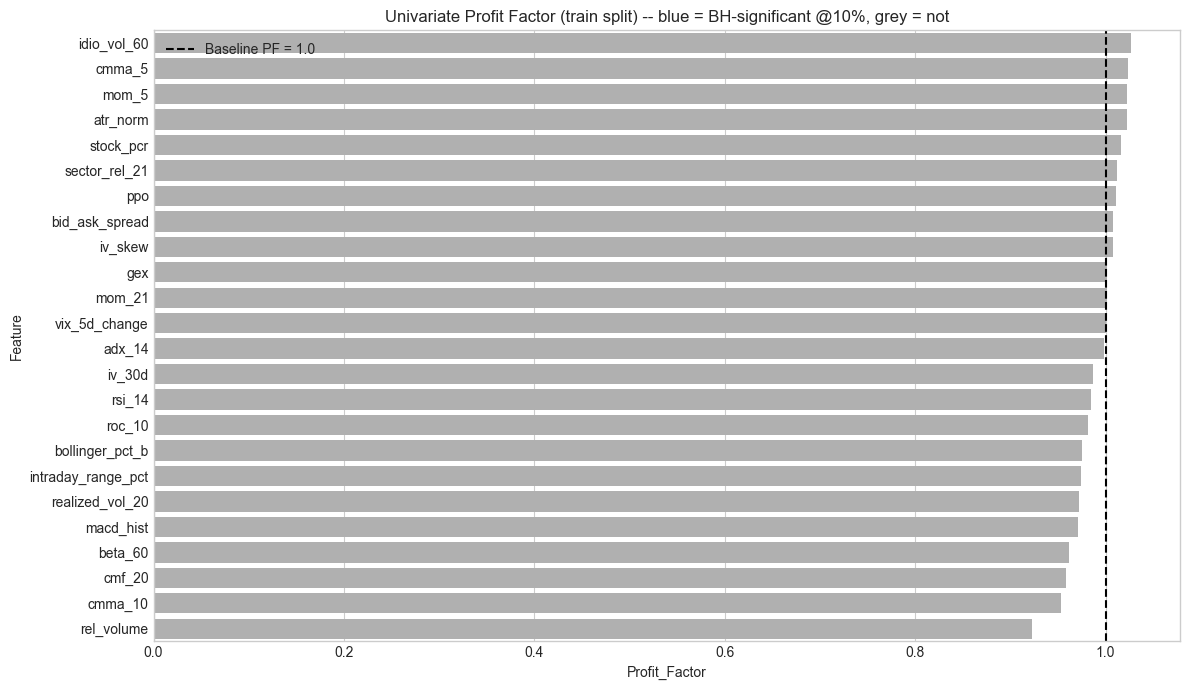

In [78]:
print("Full feature ranking (Profit Factor + Alpha + MI), computed on the training split only:")
print(rank.to_string(index=False))

plt.figure(figsize=(12, 7))
bar_colors = ["#4C72B0" if sig else "#B0B0B0" for sig in rank["BH_significant_10pct"]]
sns.barplot(data=rank, x="Profit_Factor", y="Feature", palette=bar_colors, dodge=False)
plt.axvline(1.0, color="black", linestyle="--", label="Baseline PF = 1.0")
plt.title("Univariate Profit Factor (train split) -- blue = BH-significant @10%, grey = not")
plt.legend()
plt.tight_layout()
plt.show()

No individual indicator passed the significance battery; the ranking is used only as a coarse pre-filter, and information — if any — must be extracted multivariately

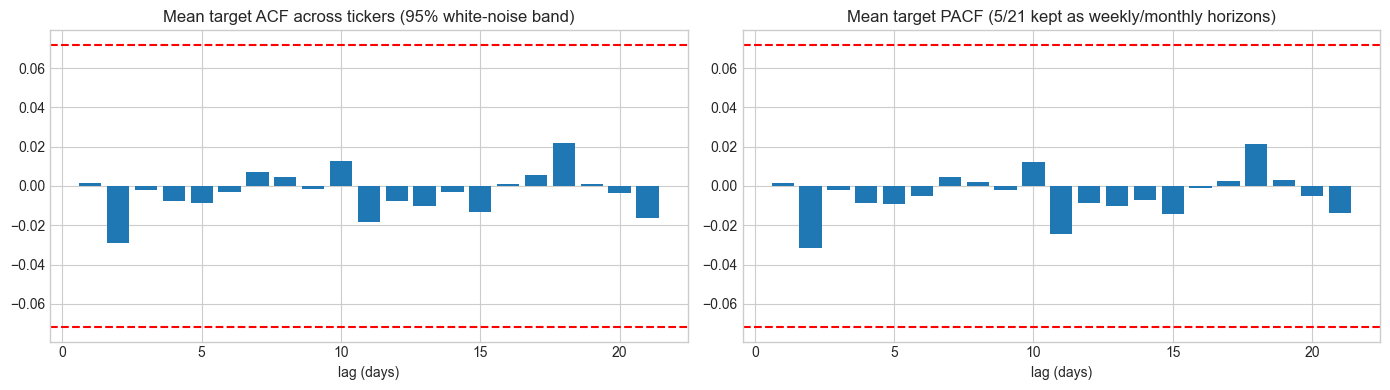

White-noise |PACF| floor ~ 0.029 (per-ticker sample size)
Strongest mean |PACF| lags (compare against that floor):
11    0.042
15    0.041
3     0.038
1     0.038
10    0.037
2     0.037
13    0.034
7     0.033
dtype: float64

Ljung-Box(10) p<0.05 for 4/20 tickers (~1 expected by chance at 5%)

Avg pairwise target correlation: -0.040 (mechanical floor from daily demeaning: -0.053)
Residual co-movement above the floor: +0.012 (small positive = names still share a common factor, e.g. size)
Independent decision units ~ 741 daily cross-sections -> treat all p-values as indicative; CV must be grouped by date

Target mean/std by year (drift-free by construction):
      mean      std  count
year                      
2022  -0.0  0.02730   4880
2023   0.0  0.02223   5000
2024  -0.0  0.02190   4940


In [ ]:
# =====================================================================
# Diagnostics: serial dependence, cross-sectional dependence, drift
# (train split ONLY -- anything that could inform modelling choices must
#  never touch the held-out test window)

#   1) ACF/PACF of the per-ticker target -> validates the "log-differencing
#      + cross-sectional demeaning already removes trend / serial structure"
#      claim. It also CHECKS the proposal's "PACF informs the lags" wording:
#      empirically the daily target is near white noise, so mom_5 / mom_21 are
#      kept as weekly/monthly conventions, not PACF-selected peaks.
#   2) Ljung-Box per ticker (pre-model serial-dependence screen).
#   3) Cross-sectional correlation of the names -> effective sample size,
#      and the reason CV must be grouped by date.
#   4) Target mean/std by year -> drift-free by construction.
# =====================================================================

from statsmodels.tsa.stattools import acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

MAX_LAG = 21
per_ticker = {tkr: g.sort_values("Date")["target"].to_numpy()
              for tkr, g in train_df.groupby("Ticker")}


# 1) ACF / PACF averaged across tickers
acf_mat  = np.vstack([acf(r, nlags=MAX_LAG, fft=True)[1:] for r in per_ticker.values()])
pacf_mat = np.vstack([pacf(r, nlags=MAX_LAG)[1:] for r in per_ticker.values()])
lags = np.arange(1, MAX_LAG + 1)
band = 1.96 / np.sqrt(len(next(iter(per_ticker.values()))))  # white-noise 95% band

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(lags, acf_mat.mean(axis=0))
axes[0].axhline(band, color="red", ls="--"); axes[0].axhline(-band, color="red", ls="--")
axes[0].set_title("Mean target ACF across tickers (95% white-noise band)")
axes[1].bar(lags, pacf_mat.mean(axis=0))
axes[1].axhline(band, color="red", ls="--"); axes[1].axhline(-band, color="red", ls="--")
axes[1].set_title("Mean target PACF (5/21 kept as weekly/monthly horizons)")
for ax in axes:
    ax.set_xlabel("lag (days)")
plt.tight_layout(); plt.show()

# Under no predictability at all, mean |PACF| ~ sqrt(2/pi)/sqrt(T)
noise_floor = np.sqrt(2 / np.pi) / np.sqrt(len(next(iter(per_ticker.values()))))
top_pacf = (pd.Series(np.abs(pacf_mat).mean(axis=0), index=lags)
            .sort_values(ascending=False).head(8).round(3))
print(f"White-noise |PACF| floor ~ {noise_floor:.3f} (per-ticker sample size)")
print("Strongest mean |PACF| lags (compare against that floor):"); print(top_pacf)

# 2) Ljung-Box per ticker
lb_p = pd.Series({tkr: acorr_ljungbox(r, lags=[10])["lb_pvalue"].iloc[0]
                    for tkr, r in per_ticker.items()})
print(f"\nLjung-Box(10) p<0.05 for {int((lb_p < 0.05).sum())}/{len(per_ticker)} tickers "
        f"(~1 expected by chance at 5%)")

# 3) Cross-sectional dependence
# NOTE: the target is demeaned across tickers each day, so the 20 series sum
# to zero BY CONSTRUCTION -> the average pairwise correlation is mechanically
# forced toward -1/(N-1). The informative quantity is how far the observed
# average sits ABOVE that floor (residual co-movement the demeaning did not
# remove). (An earlier "effective N" design-effect formula printed nonsense
# here -- larger than nominal rows -- because it assumes positive rho; removed.)
wide = train_df.pivot_table(index="Date", columns="Ticker", values="target")
corr = wide.corr().values
K = wide.shape[1]
off_diag = corr[~np.eye(K, dtype=bool)]
rho_bar = off_diag.mean()
rho_floor = -1.0 / (K - 1)
print(f"\nAvg pairwise target correlation: {rho_bar:.3f} "
      f"(mechanical floor from daily demeaning: {rho_floor:.3f})")
print(f"Residual co-movement above the floor: {rho_bar - rho_floor:+.3f} "
      "(small positive = names still share a common factor, e.g. size)")
print(f"Independent decision units ~ {wide.shape[0]:,} daily cross-sections "
      f"-> treat all p-values as indicative; "
      "CV must be grouped by date")

# 4) Drift check by calendar year
print("\nTarget mean/std by year (drift-free by construction):")
print(train_df.assign(year=train_df["Date"].dt.year)
      .groupby("year")["target"].agg(["mean", "std", "count"]).round(5))

In [ ]:
# 5) Ljung-Box p-values below 0.05 (indicating serial dependence) are flagged for further investigation. 
failing_tickers = lb_p[lb_p < 0.05]
print(failing_tickers)

CNXC    0.005818
MDU     0.001866
RGA     0.019641
USLM    0.006347
dtype: float64


## drop redundant features

Rule A (direction failure): the fit-half direction LOST money on the eval half with some conviction (alpha < 0 and |t| > T_FAIL) -- these features inject anti-signal.

Rule B (redundancy): among candidate pairs with |Spearman rho| > RHO_MAX on the train split, keep only the higher-eval-half-PF member -- a correlated twin adds estimation variance, not information.

In [85]:
# --- Tier-1 drop decision: rules first, the count emerges ----------------

RHO_MAX = 0.70   # redundancy threshold (train-split Spearman)
T_FAIL  = 1.5    # |t-stat| bar for a convicted direction failure

# --- Rule A: direction failures ---
direction_failures = sorted(
    [f for f in candidate_cols
     if scores[f]["alpha"] < 0 and abs(scores[f]["tstat"]) > T_FAIL],
    key=lambda f: scores[f]["tstat"])  # worst first
print(f"Rule A -- direction failures (alpha < 0 with |t| > {T_FAIL}):")
for f in direction_failures:
    print(f"  {f:<18} alpha={scores[f]['alpha']:+.3f}  t={scores[f]['tstat']:+.2f}")
if not direction_failures:
    print("  (none)")

# --- Rule B: redundancy pruning (greedy; keep highest-PF member per pair) ---
corr_matrix = train_df[candidate_cols].corr(method="spearman")
cols_by_pf = sorted(candidate_cols, key=lambda f: pf[f], reverse=True)
kept, redundancy_drops = [], {}
for a in cols_by_pf:
    if a in kept or a in redundancy_drops:
        continue
    kept.append(a)
    for b in candidate_cols:
        if b == a or b in kept or b in redundancy_drops:
            continue
        if abs(corr_matrix.loc[a, b]) > RHO_MAX:
            redundancy_drops[b] = (a, corr_matrix.loc[a, b])

print(f"\nRule B -- redundant twins (|rho| > {RHO_MAX}; keep the higher-PF member):")
for b, (a, rho) in sorted(redundancy_drops.items(), key=lambda kv: -abs(kv[1][1])):
    print(f"  drop {b:<18} (rho={rho:+.2f} vs kept {a})")
if not redundancy_drops:
    print("  (none)")

# --- Assemble the cut ---
dropped_features = sorted(set(direction_failures) | set(redundancy_drops.keys()))
kept_candidate_cols = [f for f in candidate_cols if f not in dropped_features]
selected_feature_cols = kept_candidate_cols + calendar_cols  # calendar always protected

mode = "rule-based"
print(f"\nDECISION ({mode}): dropped {len(dropped_features)} -> {dropped_features}")
print(f"Selected feature set ({len(selected_feature_cols)} columns: "
      f"{len(kept_candidate_cols)} candidates + {len(calendar_cols)} calendar)")
print("Exogenous features kept:",
      [f for f in exog_risk_cols + option_cols + macro_cols if f in kept_candidate_cols])

Rule A -- direction failures (alpha < 0 with |t| > 1.5):
  rel_volume         alpha=-0.143  t=-2.25

Rule B -- redundant twins (|rho| > 0.7; keep the higher-PF member):
  drop mom_21             (rho=+0.89 vs kept ppo)
  drop cmma_10            (rho=+0.82 vs kept cmma_5)
  drop bollinger_pct_b    (rho=+0.81 vs kept roc_10)
  drop macd_hist          (rho=+0.80 vs kept roc_10)
  drop realized_vol_20    (rho=+0.79 vs kept idio_vol_60)
  drop iv_30d             (rho=+0.79 vs kept idio_vol_60)
  drop mom_5              (rho=+0.78 vs kept cmma_5)
  drop rsi_14             (rho=+0.71 vs kept ppo)

DECISION (rule-based): dropped 9 -> ['bollinger_pct_b', 'cmma_10', 'iv_30d', 'macd_hist', 'mom_21', 'mom_5', 'realized_vol_20', 'rel_volume', 'rsi_14']
Selected feature set (21 columns: 15 candidates + 6 calendar)
Exogenous features kept: ['beta_60', 'idio_vol_60', 'sector_rel_21', 'stock_pcr', 'iv_skew', 'gex', 'bid_ask_spread', 'vix_5d_change']


In [86]:
# Export the engineered panel
out = df[df["Date"].isin(df_analysis["Date"])][
    ["Date", "Ticker", "target"] + selected_feature_cols
].reset_index(drop=True)
out.to_csv("modeling_panel.csv", index=False)

# Persist the split boundary + embargo so the modelling notebook can
# reproduce the exact same train/test windows.
meta = pd.DataFrame({
    "split_boundary": [split_date],
    "embargo_bdays": [EMBARGO.n],
    "train_end": [train_df["Date"].max()],
    "test_start": [test_df["Date"].min()],
    "features": [",".join(selected_feature_cols)],
})
meta.to_csv("modeling_panel_meta.csv", index=False)
print(f"Exported {out.shape[0]:,} rows x {out.shape[1]} cols -> modeling_panel.csv")
print(f"Split meta -> modeling_panel_meta.csv (boundary {split_date.date()}, "
        f"{EMBARGO.n}-bd embargo, {len(selected_feature_cols)} features)")

Exported 19,900 rows x 24 cols -> modeling_panel.csv
Split meta -> modeling_panel_meta.csv (boundary 2024-12-30, 5-bd embargo, 21 features)
